In [1]:
%matplotlib widget
%load_ext autoreload
%autoreload 2

from _path import NB_DIR
import sys
import os
from datetime import datetime
import pickle
import dill
import random
from typing import Optional

sys.path.append(str(NB_DIR))

import torch

from botorch.optim import optimize_acqf
from botorch.sampling.normal import SobolQMCNormalSampler
from botorch.acquisition.monte_carlo import qExpectedImprovement
from botorch.acquisition.objective import ConstrainedMCObjective, LinearMCObjective
from botorch.models import ModelListGP, SingleTaskGP, HeteroskedasticSingleTaskGP
from botorch import fit_gpytorch_mll
from gpytorch.mlls.sum_marginal_log_likelihood import SumMarginalLogLikelihood
from gpytorch.mlls import ExactMarginalLogLikelihood

from matal.utils import load_cache
from matal.configs import DATA_DIR
from matal.utils.datatype import to_torch
from sklearn.preprocessing import StandardScaler

import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

from matal.recipe import UniformCompositionGenerator, get_rand_comp
from matal.utils import auto_log, get_sid, obj_to_hash, merge_update, Bunch, cache_return, load_cache, save_cache
from matal.configs import BATCH_DIR, PROJ_CODE, MODEL_DIR, DATA_DIR
from matal.robot.ot2 import OT2ProcGeneratorV7

try:
    from sklearn.utils._testing import ignore_warnings
except ImportError:
    from sklearn.utils.testing import ignore_warnings

INFO:numexpr.utils:NumExpr defaulting to 8 threads.


## 0. Load SVM models

In [2]:
svm_models = load_cache('svm_models_v8')
display(svm_models)

X_COLS = ['cons_ZnCl2', 'cons_ZnOTF2', 'ratio_MeOH']
X_LIMS = np.array([35.0, 6.0, 1.0])

from matal.vis import marching_cubes, skimg_tri_to_poly, poly_to_skimg_tri, smooth_pvs_poly, get_mesh_pred

margin = 0.05
n_points = 331
pred_sol, grid_space, flattened = get_mesh_pred(svm_models['solubility'], margin=margin, n_points=n_points, target='pred')
pred_her, _, _ = get_mesh_pred(svm_models['HER'], margin=margin, n_points=n_points, target='pred', margin_value=-5.0)
pred_oer, _, _ = get_mesh_pred(svm_models['OER'], margin=margin, n_points=n_points, target='pred', margin_value= 5.0)

# Value cutoff 
oer_cutoff = 1.74
her_cutoff = -0.86

merge_pred = ((pred_sol >= 0.5) & (pred_oer >= oer_cutoff) & (pred_her >= her_cutoff)).astype(np.float16)
verts, faces, *_ = marching_cubes(merge_pred, 0.5, spacing=(grid_space, ) * 3, gradient_direction='ascent', allow_degenerate=False)
verts -= margin

# Smooth iso-plane
poly = skimg_tri_to_poly(verts, faces)
smooth_poly = smooth_pvs_poly(poly, sm_iters=500, sm_rlx=0.2, sm2_iters=50, sm2_rlx=0.05, dp_factor=0.95, dp_angle=120, dp_iters=100)
smooth_verts, smooth_faces = poly_to_skimg_tri(smooth_poly)
print(f'Num of edge points:', len(smooth_verts))

# Precalculated kDTree for fast distance computation
import scipy
kdtree = scipy.spatial.KDTree(smooth_verts)

## Low res version for plotting GP model output
_n_points = 51
_pred_sol, _, _flattened = get_mesh_pred(svm_models['solubility'], margin=0, n_points=_n_points, target='pred')
_pred_her, _, _ = get_mesh_pred(svm_models['HER'], margin=0, n_points=_n_points, target='pred', margin_value=-5.0)
_pred_oer, _, _ = get_mesh_pred(svm_models['OER'], margin=0, n_points=_n_points, target='pred', margin_value= 5.0)
_mask = (_pred_sol >= 0.5) & (_pred_oer >= oer_cutoff) & (_pred_her >= her_cutoff)
low_res_X = _flattened[_mask.reshape(-1)].astype(np.float64)
del _n_points, _pred_sol, _flattened, _pred_her, _mask
low_res_X

{'solubility': SVC(C=859.5792940061186, gamma=3.4589836312369657, probability=True,
     random_state=0),
 'HER': SVR(C=6.242440709438059, epsilon=0.004211530744928162, gamma=0.6547642454463255),
 'OER': SVR(C=2.8195945113291416, epsilon=7.409655120425588e-05,
     gamma=2.589799492724016)}

Num of edge points: 18273


array([[0.        , 0.36000001, 0.98000002],
       [0.        , 0.36000001, 1.        ],
       [0.        , 0.38      , 0.92000002],
       ...,
       [0.83999997, 0.        , 0.31999999],
       [0.83999997, 0.        , 0.34      ],
       [0.86000001, 0.        , 0.18000001]])

## 1. Train Gaussian Process models for CE and conductivity 

#### Scale CE using a custom ce_log() function to focus on changes >99%

> https://www.desmos.com/calculator/z0so28skga 


In [3]:
# baseline value when CE = 99%. Choose a baseline value = 2 to make the function always positive within [0, 100)
CE_LOG_BASELINE = 2

def ce_log(x):
    return CE_LOG_BASELINE - np.log10(100 - x)

def inv_ce_log(x):
    return 100 - np.power(10, CE_LOG_BASELINE - x)

_x = np.linspace(0, 100, num=1000000, endpoint=False)
assert np.allclose(_x, inv_ce_log(ce_log(_x)))
del _x

In [4]:
pd.concat([
    pd.read_excel(DATA_DIR / 'Round 1.xlsx'),
    pd.read_excel(DATA_DIR / 'Round 2.xlsx', na_values='>>100'),
    pd.read_excel(DATA_DIR / 'Round 3.xlsx')
], ignore_index=True)

,sample_sid,cons_ZnCl2(m),cons_ZnOTF2(m),ratio_MeOH(wt%),Conductivity(mS/cm),CE-1(%),CE-2(%),CE-3(%)
0,aES-0101,11.7400,0.2300,0.1000,71.157495,71.671627,77.812500,78.358135
1,aES-0102,3.8000,1.8000,0.0900,92.501233,66.319444,67.926587,NaN
2,aES-0103,1.6600,2.4200,0.4100,57.515337,65.853175,64.970238,64.523810
3,aES-0104,25.1600,0.1600,0.1600,14.958117,85.163690,91.299603,88.194444
4,aES-0105,4.9100,0.2200,0.7600,32.084189,72.435516,74.866071,70.838294
5,aES-0106,17.0200,0.9300,0.8900,2.797464,97.896825,97.529762,98.888889
6,aES-0107,1.2900,3.6400,0.7200,18.098456,72.781500,75.380800,70.946700
7,aES-0108,11.2200,0.1300,0.4500,33.998187,75.322421,73.878968,74.454365
8,aES-0109,23.9600,0.1800,0.5900,4.837212,95.347222,93.526786,95.099206
9,aES-010A,1.9100,2.0600,0.9500,20.491803,86.443452,90.109127,94.186508


In [5]:
def get_date():
    data_df = pd.concat([
        pd.read_excel(DATA_DIR / 'Round 1.xlsx'),
        pd.read_excel(DATA_DIR / 'Round 2.xlsx', na_values='>>100'),
        pd.read_excel(DATA_DIR / 'Round 3.xlsx')
    ], ignore_index=True)
    CE_COLS = ['CE-1(%)', 'CE-2(%)', 'CE-3(%)']
    TOPTWO_CE_COLS = ['CE-T1(%)', 'CE-T2(%)', ]
    LOG_TOPTWO_CE_COLS = ['LgCE-T1(-)', 'LgCE-T2(-)', ]

    data_df[TOPTWO_CE_COLS] = data_df[CE_COLS].fillna(0).apply(lambda x: np.sort(x)[::-1][:2], axis=1,
                                                               result_type='expand')
    data_df['CE-T2(%)'] = data_df[TOPTWO_CE_COLS].apply(lambda x: x[0] if x[1] == 0.0 else x[1], axis=1)
    data_df[LOG_TOPTWO_CE_COLS] = ce_log(data_df[TOPTWO_CE_COLS])

    data_df['LgCE_Mean'] = data_df[LOG_TOPTWO_CE_COLS].mean(axis=1)
    data_df['LgCE_Var'] = np.clip(data_df[LOG_TOPTWO_CE_COLS].var(axis=1, ddof=0), 1e-4, None)
    data_df['Conductivity_Mean'] = data_df['Conductivity(mS/cm)']
    data_df['Conductivity_Var'] = 1e-4

    lce_scaler = StandardScaler().fit(data_df[['LgCE_Mean']])
    con_scaler = StandardScaler().fit(data_df[['Conductivity_Mean']])

    data_df[['Scaled_LgCE_Mean']] = lce_scaler.transform(data_df[['LgCE_Mean']])
    data_df[['Scaled_LgCE_Var']] = data_df[['LgCE_Var']] / lce_scaler.scale_
    data_df[['Scaled_Conductivity_Mean']] = con_scaler.transform(data_df[['Conductivity_Mean']])
    data_df[['Scaled_Conductivity_Var']] = data_df[['Conductivity_Var']] / con_scaler.scale_

    cond_cutoff = con_scaler.transform([[10]])[0, 0]
    return data_df, lce_scaler, con_scaler, cond_cutoff


def set_seed(seed):
    torch.manual_seed(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.use_deterministic_algorithms(True)


def build_model(data_df, random_seed=None):
    set_seed(random_seed)

    X_COLS = ['cons_ZnCl2(m)', 'cons_ZnOTF2(m)', 'ratio_MeOH(wt%)']
    X_LIMS = np.array([35.0, 6.0, 1.0])
    train_x = to_torch(data_df[X_COLS] / X_LIMS)
    model_lce = SingleTaskGP(
        train_X=train_x,
        train_Y=to_torch(data_df[['Scaled_LgCE_Mean']]),
        train_Yvar=to_torch(data_df[['Scaled_LgCE_Var']]),
    )

    model_con = SingleTaskGP(
        train_X=train_x,
        train_Y=to_torch(data_df[['Scaled_Conductivity_Mean']]),
        train_Yvar=to_torch(data_df[['Scaled_Conductivity_Var']]),
    ).to(train_x)
    model = ModelListGP(model_lce, model_con)
    mll = SumMarginalLogLikelihood(model.likelihood, model)
    fit_gpytorch_mll(mll, max_retries=50, )

    return model, mll


def build_single_output_models(data_df, random_seed=None):
    set_seed(random_seed)

    X_COLS = ['cons_ZnCl2(m)', 'cons_ZnOTF2(m)', 'ratio_MeOH(wt%)']
    X_LIMS = np.array([35.0, 6.0, 1.0])
    train_x = to_torch(data_df[X_COLS] / X_LIMS)
    model_lce = SingleTaskGP(
        train_X=train_x,
        train_Y=to_torch(data_df[['Scaled_LgCE_Mean']]),
        train_Yvar=to_torch(data_df[['Scaled_LgCE_Var']]),
    )

    model_con = SingleTaskGP(
        train_X=train_x,
        train_Y=to_torch(data_df[['Scaled_Conductivity_Mean']]),
        train_Yvar=to_torch(data_df[['Scaled_Conductivity_Var']]),
    ).to(train_x)

    kwargs = dict(max_attempts=1024, pick_best_of_all_attempts=True,)
    mll_lce = ExactMarginalLogLikelihood(model_lce.likelihood, model_lce)
    mll_con = ExactMarginalLogLikelihood(model_con.likelihood, model_con)
    fit_gpytorch_mll(mll_lce, **kwargs)
    fit_gpytorch_mll(mll_con, **kwargs)

    return model_lce, mll_lce, model_con, mll_con


data_df, lce_scaler, con_scaler, cond_cutoff = get_date()
print('Scaled conductivity cutoff =', cond_cutoff)

RANDOM_SEED = 0
model, mll = build_model(data_df, random_seed=RANDOM_SEED)
model_lce, mll_lce, model_con, mll_con = build_single_output_models(data_df, random_seed=RANDOM_SEED)
data_df


/Users/liyang/miniconda3/envs/battery/lib/python3.10/site-packages/sklearn/base.py:464: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/Users/liyang/miniconda3/envs/battery/lib/python3.10/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.4608e-16], dtype=torch.float64), std = tensor([1.0134], dtype=torch.float64)). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


Scaled conductivity cutoff = -0.6925638452153946


/Users/liyang/miniconda3/envs/battery/lib/python3.10/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([4.6746e-17], dtype=torch.float64), std = tensor([1.0134], dtype=torch.float64)). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/Users/liyang/miniconda3/envs/battery/lib/python3.10/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.4608e-16], dtype=torch.float64), std = tensor([1.0134], dtype=torch.float64)). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/Users/liyang/miniconda3/envs/battery/lib/python3.10/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([4.6746e-17], dtype=torch.float64), std = tensor([1.0134], dtype=torch.float64)). Please consider scaling the input to 

,sample_sid,cons_ZnCl2(m),cons_ZnOTF2(m),ratio_MeOH(wt%),Conductivity(mS/cm),CE-1(%),CE-2(%),CE-3(%),CE-T1(%),CE-T2(%),LgCE-T1(-),LgCE-T2(-),LgCE_Mean,LgCE_Var,Conductivity_Mean,Conductivity_Var,Scaled_LgCE_Mean,Scaled_LgCE_Var,Scaled_Conductivity_Mean,Scaled_Conductivity_Var
0,aES-0101,11.7400,0.2300,0.1000,71.157495,71.671627,77.812500,78.358135,78.358135,77.812500,0.664705,0.653892,0.659298,0.000100,71.157495,0.0001,-0.560335,0.000097,1.602009,0.000004
1,aES-0102,3.8000,1.8000,0.0900,92.501233,66.319444,67.926587,NaN,67.926587,66.319444,0.493855,0.472621,0.483238,0.000113,92.501233,0.0001,-0.731132,0.000109,2.402806,0.000004
2,aES-0103,1.6600,2.4200,0.4100,57.515337,65.853175,64.970238,64.523810,65.853175,64.970238,0.466650,0.455563,0.461106,0.000100,57.515337,0.0001,-0.752602,0.000097,1.090168,0.000004
3,aES-0104,25.1600,0.1600,0.1600,14.958117,85.163690,91.299603,88.194444,91.299603,88.194444,1.060461,0.927914,0.994187,0.004392,14.958117,0.0001,-0.235459,0.004261,-0.506540,0.000004
4,aES-0105,4.9100,0.2200,0.7600,32.084189,72.435516,74.866071,70.838294,74.866071,72.435516,0.599740,0.559650,0.579695,0.000402,32.084189,0.0001,-0.637559,0.000390,0.136015,0.000004
5,aES-0106,17.0200,0.9300,0.8900,2.797464,97.896825,97.529762,98.888889,98.888889,97.896825,1.954243,1.677125,1.815684,0.019199,2.797464,0.0001,0.561475,0.018625,-0.962796,0.000004
6,aES-0107,1.2900,3.6400,0.7200,18.098456,72.781500,75.380800,70.946700,75.380800,72.781500,0.608726,0.565136,0.586931,0.000475,18.098456,0.0001,-0.630539,0.000461,-0.388717,0.000004
7,aES-0108,11.2200,0.1300,0.4500,33.998187,75.322421,73.878968,74.454365,75.322421,74.454365,0.607697,0.592683,0.600190,0.000100,33.998187,0.0001,-0.617676,0.000097,0.207826,0.000004
8,aES-0109,23.9600,0.1800,0.5900,4.837212,95.347222,93.526786,95.099206,95.347222,95.099206,1.332288,1.309734,1.321011,0.000127,4.837212,0.0001,0.081592,0.000123,-0.886267,0.000004
9,aES-010A,1.9100,2.0600,0.9500,20.491803,86.443452,90.109127,94.186508,94.186508,90.109127,1.235563,1.004765,1.120164,0.013317,20.491803,0.0001,-0.113249,0.012919,-0.298921,0.000004


In [6]:
save_cache(dict(
    model=model, 
    mll=mll, 
    model_lce=model_lce, 
    mll_lce=mll_lce, 
    model_con=model_con, 
    mll_con=mll_con,
    lce_scaler=lce_scaler,
    con_scaler=con_scaler,
    data_df=data_df,
    x_cols=['cons_ZnCl2(m)', 'cons_ZnOTF2(m)', 'ratio_MeOH(wt%)'],
    x_lims=X_LIMS
), 'optimization_model_round_05')

In [7]:
data_df.sort_values('LgCE_Mean', ascending=False, )[:10]

,sample_sid,cons_ZnCl2(m),cons_ZnOTF2(m),ratio_MeOH(wt%),Conductivity(mS/cm),CE-1(%),CE-2(%),CE-3(%),CE-T1(%),CE-T2(%),LgCE-T1(-),LgCE-T2(-),LgCE_Mean,LgCE_Var,Conductivity_Mean,Conductivity_Var,Scaled_LgCE_Mean,Scaled_LgCE_Var,Scaled_Conductivity_Mean,Scaled_Conductivity_Var
14,aES-0203,13.4106,0.5104,0.9916,3.073770,99.995040,99.999504,99.999504,99.999504,99.999504,5.304491,5.304491,5.304491,0.000100,3.073770,0.0001,3.945969,0.000097,-0.952430,0.000004
20,aES-0209,21.8209,0.1858,1.0000,1.932990,99.925595,99.999504,99.960317,99.999504,99.960317,5.304491,3.401401,4.352946,0.905438,1.932990,0.0001,3.022875,0.878366,-0.995231,0.000004
35,aES-030C,16.7600,0.3100,0.9800,3.205128,99.692460,99.871032,99.826389,99.871032,99.826389,2.889517,2.760422,2.824970,0.004166,3.205128,0.0001,1.540584,0.004042,-0.947501,0.000004
13,aES-0202,17.0880,1.2598,0.9062,2.604167,99.444444,99.469246,99.727183,99.727183,99.469246,2.564128,2.275107,2.419617,0.020883,2.604167,0.0001,1.147351,0.020259,-0.970049,0.000004
29,aES-0306,11.0400,2.3300,0.8400,3.537736,99.077381,99.176587,99.305556,99.305556,99.176587,2.158362,2.084382,2.121372,0.001368,3.537736,0.0001,0.858024,0.001327,-0.935022,0.000004
34,aES-030B,9.1100,0.3600,0.9800,9.328358,98.963294,99.032738,98.958333,99.032738,98.963294,2.014456,1.984344,1.999400,0.000227,9.328358,0.0001,0.739698,0.000220,-0.717763,0.000004
5,aES-0106,17.0200,0.9300,0.8900,2.797464,97.896825,97.529762,98.888889,98.888889,97.896825,1.954243,1.677125,1.815684,0.019199,2.797464,0.0001,0.561475,0.018625,-0.962796,0.000004
21,aES-020A,19.9238,1.4532,0.5998,6.067961,97.822421,97.946429,97.450397,97.946429,97.822421,1.687490,1.662026,1.674758,0.000162,6.067961,0.0001,0.424763,0.000157,-0.840090,0.000004
27,aES-0304,10.7400,2.8800,0.7500,3.750000,95.461310,97.524802,98.030754,98.030754,97.524802,1.705700,1.606390,1.656045,0.002466,3.750000,0.0001,0.406609,0.002392,-0.927058,0.000004
18,aES-0207,19.2147,0.0605,0.6085,8.928571,94.965278,98.293651,NaN,98.293651,94.965278,1.767932,1.298024,1.532978,0.055203,8.928571,0.0001,0.287222,0.053553,-0.732763,0.000004


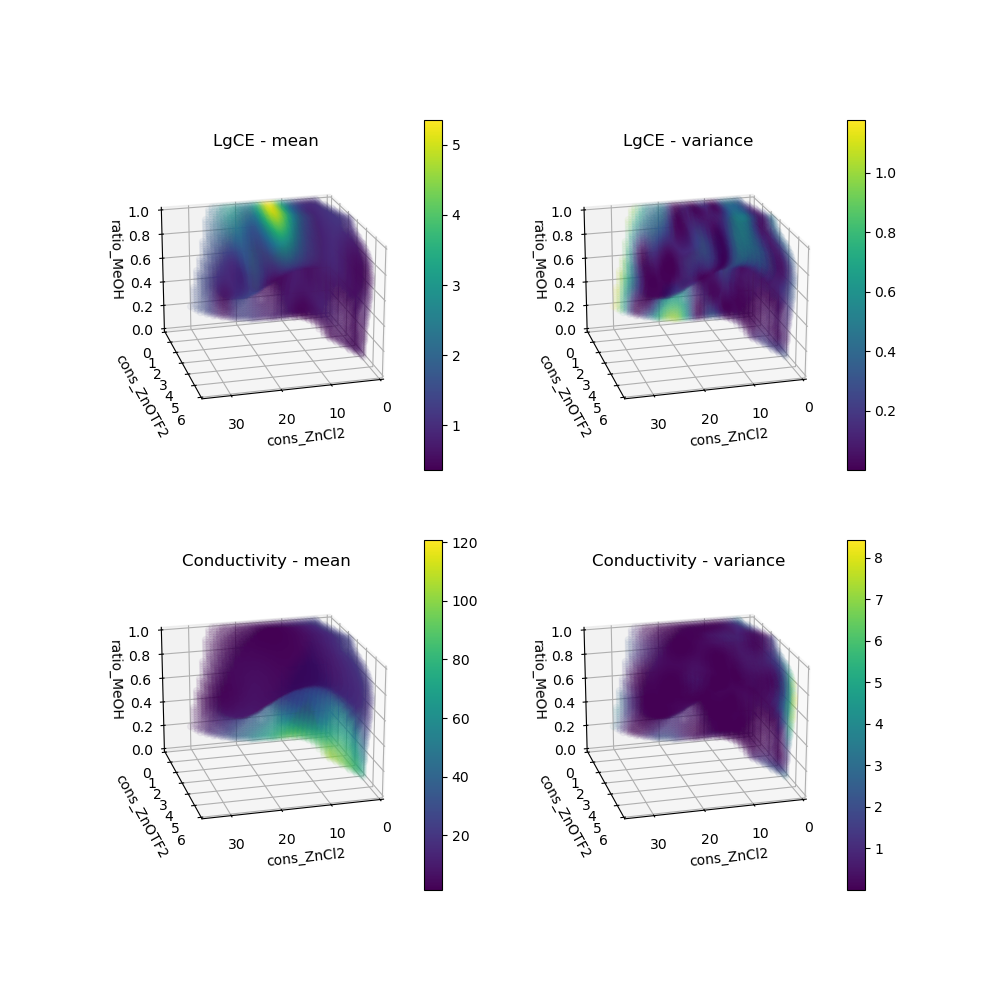

In [8]:
lce_preds = model_lce(to_torch(low_res_X))
con_preds = model_con(to_torch(low_res_X))


plt.close('all')
fig, axs = plt.subplots(2, 2, subplot_kw=dict(projection='3d'), figsize=(10, 10))

for axr, slice_i, ylabel, scaler, preds in [
    (axs[0], 0, 'LgCE',         lce_scaler, lce_preds),
    (axs[1], 1, 'Conductivity', con_scaler, con_preds),
]:
    for ax, val_type in [(axr[0], 'mean'), (axr[1], 'variance'), ]:
        vals = getattr(preds, val_type).detach().numpy()
        if val_type == 'mean':
            vals = scaler.inverse_transform(vals.reshape(-1, 1)).reshape(-1)
        elif val_type == 'variance':
            vals = vals * scaler.scale_[0]
        sc = ax.scatter(*(low_res_X * X_LIMS).T, c=vals, alpha=0.05)
        cbar = plt.colorbar(sc, ax=ax)
        cbar.solids.set(alpha=1)
        
        [getattr(ax, f'set_{a}label')(c) for a, c in zip('xyz', X_COLS)]
        [getattr(ax, f'set_{a}lim')(0, l) for a, l in zip('xyz', X_LIMS)]
        ax.view_init(20, 75)

        ax.set_title(f'{ylabel} - {val_type}')

## 2. Define acquisition functions constrained by conductivity

In [9]:
dtype = torch.double

from botorch.acquisition.analytic import ExpectedImprovement, ProbabilityOfImprovement


aqcfs = {}


for bound_tag, lo, hi in [
    ('c01', 1, 2),
    ('c02', 2, 3), 
    ('c03', 3, 4),
    ('c04', 4, 5), 
    ('c05', 5, 6), 
    ('c06', 6, 7), 
    ('c07', 7, 8), 
    ('c08', 8, 9), 
    ('c09', 9, 10), 
    ('c10', 10, np.inf), 
]:
    for aqcf_name, aqcf_cls in [('EI', ExpectedImprovement), ('PI', ProbabilityOfImprovement)]:
        sub_df = data_df[(lo <= data_df.Conductivity_Mean) & (data_df.Conductivity_Mean < hi)]
        best_f = sub_df.Scaled_LgCE_Mean.max()
        aqcf = aqcf_cls(model=model_lce, best_f=best_f)
        tag = f'{aqcf_name}_{bound_tag}'
        aqcfs[tag] = [aqcf, lo, hi, best_f]
     
for bound_tag, lo, hi in [('m45', 0.4, 0.45),
                          ('m50', 0.45, 0.5), 
                          ('m55', 0.50, 0.55), 
                          ('m60', 0.55, 0.60), 
                          ('m65', 0.60, 0.65), 
                          ('m70', 0.65, 0.70), 
                          ('m75', 0.70, 0.75), 
                          ('m80', 0.75, 0.80), 
                          ('m85', 0.80, 0.85),
                          ('m90', 0.85, 0.90),
                          ('m95', 0.90, 0.95),
                         ]:
    for aqcf_name, aqcf_cls in [('EI', ExpectedImprovement), ('PI', ProbabilityOfImprovement)]:
        sub_df = data_df[(lo <= data_df['ratio_MeOH(wt%)']) & (data_df['ratio_MeOH(wt%)'] < hi)]
        best_f = sub_df.Scaled_LgCE_Mean.max()
        aqcf = aqcf_cls(model=model_lce, best_f=best_f)
        tag = f'{aqcf_name}_{bound_tag}'
        aqcfs[tag] = [aqcf, lo, hi, best_f]
             
for bound_tag, lo, hi in [('z01', 0, 1),
                          ('z02', 1, 2),
                          ('z03', 2, 3),
                          ('z04', 3, 4),
                          ('z05', 4, 5),
                          ('z06', 5, 6),
                          ('z07', 6, 7),
                          ('z08', 7, 8), 
                          ('z09', 8, 9), 
                          ('z10', 9, 10),
                         ]:
    for aqcf_name, aqcf_cls in [('EI', ExpectedImprovement), ('PI', ProbabilityOfImprovement)]:
        sub_df = data_df[(lo <= data_df['cons_ZnCl2(m)']) & (data_df['cons_ZnCl2(m)'] < hi)]
        best_f = sub_df.Scaled_LgCE_Mean.max()
        aqcf = aqcf_cls(model=model_lce, best_f=best_f)
        tag = f'{aqcf_name}_{bound_tag}'
        aqcfs[tag] = [aqcf, lo, hi, best_f]
        
aqcfs

{'EI_c01': [ExpectedImprovement(
    (model): SingleTaskGP(
      (likelihood): FixedNoiseGaussianLikelihood(
        (noise_covar): FixedGaussianNoise()
      )
      (mean_module): ConstantMean()
      (covar_module): ScaleKernel(
        (base_kernel): MaternKernel(
          (lengthscale_prior): GammaPrior()
          (raw_lengthscale_constraint): Positive()
        )
        (outputscale_prior): GammaPrior()
        (raw_outputscale_constraint): Positive()
      )
    )
  ),
  1,
  2,
  3.0228746951372187],
 'PI_c01': [ProbabilityOfImprovement(
    (model): SingleTaskGP(
      (likelihood): FixedNoiseGaussianLikelihood(
        (noise_covar): FixedGaussianNoise()
      )
      (mean_module): ConstantMean()
      (covar_module): ScaleKernel(
        (base_kernel): MaternKernel(
          (lengthscale_prior): GammaPrior()
          (raw_lengthscale_constraint): Positive()
        )
        (outputscale_prior): GammaPrior()
        (raw_outputscale_constraint): Positive()
      )
   

In [10]:
save_cache(Bunch(
    model_con=model_con,
    con_scaler=con_scaler,
    model_lce=model_lce,
    lce_scaler=lce_scaler,
), 'gp_models_r3')

In [11]:
import copy
from scipy.spatial.distance import pdist, cdist, squareform
from tqdm.auto import tqdm


def pred_conductivity(comp):
    X = to_torch(np.array([comp / X_LIMS])).to(dtype)
    conductivity = model_con(X).mean.detach().numpy()
    conductivity = con_scaler.inverse_transform(conductivity.reshape(-1, 1)).reshape(-1)
    return conductivity[0]

def pred_lce(comp):
    X = to_torch(np.array([comp / X_LIMS])).to(dtype)
    lce = model_lce(X).mean.detach().numpy()
    lce = lce_scaler.inverse_transform(lce.reshape(-1, 1)).reshape(-1)
    return lce[0]

_LIMS = np.array([35.0, 6.0, 1.0])

@ignore_warnings(category=UserWarning)
def _pred_feasibility(comp, svm_models=svm_models, scale=X_LIMS, kdtree=None, 
                     min_dist=0, min_comp=0, her_cutoff=-0.86, oer_cutoff=1.74, 
                     max_comp=1.0):
    comp = np.array(comp) / scale
    
    if svm_models is not None:
        sol = svm_models['solubility'].predict([comp])[0]
        her = svm_models['HER'].predict([comp])[0]
        oer = svm_models['OER'].predict([comp])[0]
        result = sol & (her >= her_cutoff) & (oer >= oer_cutoff)
    else:
        result = True

    if (kdtree is not None) and (min_dist > 0.0):
        dist, min_idx = kdtree.query([comp])
        result = result & (dist[0] > min_dist)

    if min_comp > 0.0:
        result = result & (min(comp) >= min_comp)

    if max_comp < 1.0:
        result = result & (max(comp) <= max_comp)

    return 1.0 if result else 0.0


from functools import partial


pred_feasibility = partial(_pred_feasibility,
                           kdtree=kdtree, 
                           min_dist=0.00, 
                           min_comp=0.00, 
                           max_comp=1.00)

def botorch_aqcf_wrapper(aqcf):
    def fun(x):
        return -aqcf(to_torch(np.array([x]) / X_LIMS)).detach().cpu().numpy()[0]
    return fun


from scipy.optimize import NonlinearConstraint, LinearConstraint, shgo

opt_results = {}
opt_rows = []
for tag, (aqcf, lo, hi, best_f) in tqdm(aqcfs.items()):
    py_aqcf = botorch_aqcf_wrapper(aqcf)
    nc_feas = NonlinearConstraint(pred_feasibility, 0.5, 2.0)
    if '_c' in tag:
        cond = NonlinearConstraint(pred_conductivity, lo, hi)
        text = f'{lo} ≤ conductivity ≤ {hi}'
    elif '_m' in tag:
        cond = LinearConstraint(np.array([[0., 0., 1.]]), lb=lo, ub=hi)
        text = f'{lo} ≤ MeOH ≤ {hi}'
    elif '_z' in tag:
        cond = LinearConstraint(np.array([[1., 0., 0.]]), lb=lo, ub=hi)
        text = f'{lo} ≤ ZnCl2 ≤ {hi}'
    else:
        raise ValueError(tag)
    opt = shgo(py_aqcf, 
               bounds=[(0, 35.0), (0, 6.0), (0, 1.0)], 
               constraints=[nc_feas, cond],
               sampling_method='sobol',
               n=2048,
              )
    opt_results[tag] = opt
    try:
        opt_rows.append(dict(Tag=tag, Rule=text, cons_ZnCl2=opt.x[0], cons_ZnOTF2=opt.x[1], ratio_MeOH=opt.x[2],
                       Aqcf_Val=-opt.fun, LCE=pred_lce(opt.x), Conductivity=pred_conductivity(opt.x),
                       Feasibility=bool(pred_feasibility(opt.x))))
        print(pred_feasibility(opt.x))
    except TypeError as e:
        print(f'failed to find solution for {tag}: {e}')
        display(opt)
    
pd.DataFrame(opt_rows).round(4)

  0%|          | 0/62 [00:00<?, ?it/s]

failed to find solution for EI_c01: 'NoneType' object is not subscriptable


 message: Failed to find a feasible minimizer point. Lowest sampling point = None
 success: False
     fun: None
       x: None
     nit: 1
    nfev: 0
   nlfev: 0
   nljev: 0
   nlhev: 0
    tnev: 2048

failed to find solution for PI_c01: 'NoneType' object is not subscriptable


 message: Failed to find a feasible minimizer point. Lowest sampling point = None
 success: False
     fun: None
       x: None
     nit: 1
    nfev: 0
   nlfev: 0
   nljev: 0
   nlhev: 0
    tnev: 2048

INFO:root:[[0.0, 35.0], [0.0, 6.0], [0.0, 1.0]]
INFO:root:[[0.0, 35.0], [0.0, 6.0], [0.0, 1.0]]
INFO:root:[[0.0, 35.0], [0.0, 6.0], [0.0, 1.0]]
INFO:root:[[0.0, 35.0], [0.0, 6.0], [0.0, 1.0]]


... (112 outputs left out)

1.0


INFO:root:[[0.0, 35.0], [0.0, 6.0], [0.0, 1.0]]
INFO:root:[[0.0, 35.0], [0.0, 6.0], [0.0, 1.0]]


1.0


,Tag,Rule,cons_ZnCl2,cons_ZnOTF2,ratio_MeOH,Aqcf_Val,LCE,Conductivity,Feasibility
0,EI_c02,2 ≤ conductivity ≤ 3,13.4896,0.5040,1.0000,2.8469,5.3543,3.0000,True
1,PI_c02,2 ≤ conductivity ≤ 3,21.6176,0.1830,1.0000,0.8131,3.0318,2.0000,True
2,EI_c03,3 ≤ conductivity ≤ 4,13.4938,0.2941,1.0000,0.0686,5.3652,4.0000,True
3,PI_c03,3 ≤ conductivity ≤ 4,13.4313,0.4784,1.0000,0.9402,5.3563,3.1398,True
4,EI_c04,4 ≤ conductivity ≤ 5,13.4578,0.2965,1.0000,3.9238,5.3658,4.0077,True
5,PI_c04,4 ≤ conductivity ≤ 5,11.5322,1.9780,0.8383,1.0000,2.4733,4.0000,True
6,EI_c06,6 ≤ conductivity ≤ 7,13.1211,0.0000,1.0000,3.5184,5.3016,6.0000,True
7,PI_c06,6 ≤ conductivity ≤ 7,12.5610,0.3252,0.9106,1.0000,4.3452,6.0066,True
8,EI_c08,8 ≤ conductivity ≤ 9,12.7893,0.0000,0.8979,2.7279,4.3449,8.0000,True
9,PI_c08,8 ≤ conductivity ≤ 9,12.7297,0.0000,0.8981,1.0000,4.3213,8.0563,True
